Baseline MazE: 1058.282 nM

===== Perturbation 50% =====
  k_syn_mazE  : up=  524.803  down= 2126.477
  gamma_maze  : up= 2115.600  down=  529.564
  k_in        : up= 1066.070  down= 1027.567
  k_act       : up= 1066.069  down= 1027.625
  k_deact     : up= 1030.666  down= 1065.962
  gamma_arb   : up= 1027.625  down= 1066.069
  k_syn       : up= 1066.073  down= 1027.496
  gamma_arac  : up= 1025.767  down= 1066.270
  h           : up=  844.604  down= 1068.659
  K_half      : up= 1027.437  down= 1066.075
  k_syn_mazF  : up= 1063.479  down= 1047.904
  gamma_mazf  : up= 1057.800  down= 1059.128
  k_bind      : up= 1059.128  down= 1057.800
  k_unbind    : up= 1057.815  down= 1059.106
  chi_mazef   : up= 1059.106  down= 1057.815

===== Perturbation 150% =====
  k_syn_mazE  : up= 1592.303  down=  702.503
  gamma_maze  : up=  705.816  down= 1586.949
  k_in        : up= 1045.404  down= 1064.046
  k_act       : up= 1045.421  down= 1064.044
  k_deact     : up= 1063.919  down= 1046.312
  gamma_arb 

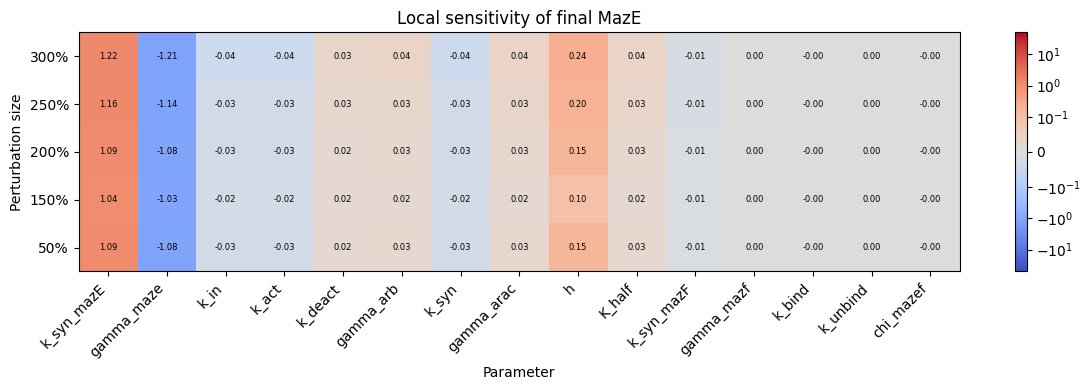

In [1]:
# ----------- MazE code ---------------

import numpy as np
import matplotlib.pyplot as plt
import math as math
from scipy.optimize import fsolve
from matplotlib.colors import SymLogNorm

base = {
'k_syn_mazE' : 28.32*2,
'gamma_maze' : 0.053,
'k_in' : 100,
'k_act' : 1e-6,
'k_deact' : 1,
'gamma_arb' : 0.06,
'k_syn' : 45.3,
'gamma_arac' : 0.0415,
'h' : 2,
'K_half' : 40,
'k_syn_mazF' : 319.149,
'gamma_mazf' : 0.03,
'k_bind' : 0.01,
'k_unbind' : 1,
'chi_mazef' : 0.03
}

def run_model(p):
    def equations(v):
        prot_maze, arb, AraC, AraC_active, prot_mazf, prot_mazef = v
        aca = max(AraC_active, 0)
        return [
            p['k_syn_mazE'] - p['gamma_maze']*prot_maze + p['k_unbind']*prot_mazef - p['k_bind']*prot_maze*prot_mazf,
            p['k_in'] - p['k_act']*arb*AraC - p['gamma_arb']*arb + p['k_deact']*AraC_active,
            p['k_syn'] - p['gamma_arac']*AraC - p['k_act']*arb*AraC + p['k_deact']*AraC_active,
            p['k_act']*arb*AraC - p['k_deact']*AraC_active - p['gamma_arac']*AraC_active,
            p['k_syn_mazF']*(aca**p['h']/(p['K_half']**p['h'] + aca**p['h'])) - p['gamma_mazf']*prot_mazf - p['k_bind']*prot_maze*prot_mazf + p['k_unbind']*prot_mazef,
            p['k_bind']*prot_maze*prot_mazf - p['k_unbind']*prot_mazef - p['chi_mazef']*prot_mazef
        ]
    initial = [0,0,0,0,0,0]
    solution, info, ier, msg = fsolve(equations, initial, full_output=True)
    if ier != 1 or any(x < -1e-6 for x in solution):
        return np.nan
    return solution[0]   # free MazE protein

baseline_output = run_model(base)
print(f"Baseline MazE: {baseline_output:.3f} nM\n")

P = [0.5, 1.5, 2, 2.5, 3]
parameters = list(base.keys())
grid = np.zeros((len(P), len(parameters)))

for row, num in enumerate(P):
  print(f"===== Perturbation {int(num*100)}% =====")
  for col, name in enumerate(parameters):
      if base[name] == 0:
          continue
      up = dict(base); up[name] = base[name]*num
      down = dict(base); down[name] = base[name]/num
      y_up = run_model(up)
      y_down = run_model(down)
      print(f"  {name:12s}: up={y_up:9.3f}  down={y_down:9.3f}")
      if not (np.isfinite(y_up) and np.isfinite(y_down)):
          grid[row, col] = np.nan
          continue
      grid[row, col] = ((y_up - y_down)/baseline_output)/(2*math.log(num))
  print()

# heat map
fig, ax = plt.subplots(figsize=(12,4))
im = ax.imshow(grid, cmap='coolwarm', aspect='auto', origin='lower',
               norm=SymLogNorm(linthresh=0.1, vmin=-50, vmax=50))
ax.set_xticks(range(len(parameters))); ax.set_xticklabels(parameters, rotation=45, ha='right')
ax.set_yticks(range(len(P)));      ax.set_yticklabels([f'{int(p*100)}%' for p in P])
ax.set_xlabel('Parameter'); ax.set_ylabel('Perturbation size')
ax.set_title('Local sensitivity of final MazE')
plt.colorbar(im, ax=ax)
for i in range(len(P)):
  for j in range(len(parameters)):
    if np.isfinite(grid[i,j]):
        ax.text(j, i, f'{grid[i, j]:.2f}', ha='center', va='center', color='k', fontsize=6)
plt.tight_layout()
plt.show()

Baseline MazF: 1.788 nM

===== Perturbation 50% =====
  k_syn_mazE  : up=    3.307  down=    0.931
  gamma_maze  : up=    0.936  down=    3.282
  k_in        : up=    0.445  down=    7.280
  k_act       : up=    0.446  down=    7.270
  k_deact     : up=    6.711  down=    0.464
  gamma_arb   : up=    7.270  down=    0.446
  k_syn       : up=    0.445  down=    7.294
  gamma_arac  : up=    7.613  down=    0.411
  h           : up=   48.276  down=    0.003
  K_half      : up=    7.304  down=    0.445
  k_syn_mazF  : up=    0.890  down=    3.608
  gamma_mazf  : up=    1.871  down=    1.641
  k_bind      : up=    3.282  down=    0.936
  k_unbind    : up=    0.962  down=    3.242
  chi_mazef   : up=    3.242  down=    0.962

===== Perturbation 150% =====
  k_syn_mazE  : up=    1.225  down=    2.577
  gamma_maze  : up=    2.567  down=    1.228
  k_in        : up=    4.051  down=    0.792
  k_act       : up=    4.048  down=    0.793
  k_deact     : up=    0.814  down=    3.890
  gamma_arb   :

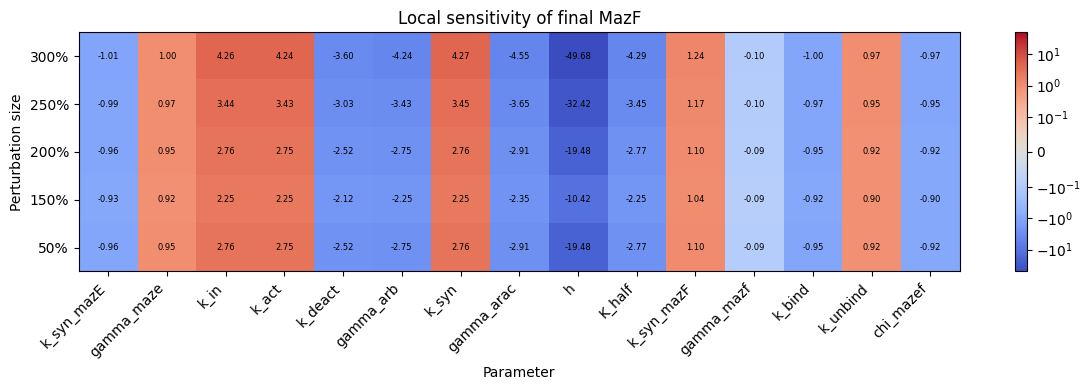

In [2]:
# ---------------- MazF code -------------------

import numpy as np
import matplotlib.pyplot as plt
import math as math
from scipy.optimize import fsolve
from matplotlib.colors import SymLogNorm

base = {
'k_syn_mazE' : 28.32*2,   # nM/min
'gamma_maze' : 0.053,
'k_in' : 100,             # guessed
'k_act' : 1e-6,           # must be much smaller than k_deact
'k_deact' : 1,
'gamma_arb' : 0.06,
'k_syn' : 45.3,
'gamma_arac' : 0.0415,
'h' : 2,
'K_half' : 40,            # guessed
'k_syn_mazF' : 319.149,
'gamma_mazf' : 0.03,
'k_bind' : 0.01,
'k_unbind' : 1,
'chi_mazef' : 0.03
}

def run_model(p):
    def equations(v):
        prot_maze, arb, AraC, AraC_active, prot_mazf, prot_mazef = v
        aca = max(AraC_active, 0)
        return [
            p['k_syn_mazE'] - p['gamma_maze']*prot_maze + p['k_unbind']*prot_mazef - p['k_bind']*prot_maze*prot_mazf,
            p['k_in'] - p['k_act']*arb*AraC - p['gamma_arb']*arb + p['k_deact']*AraC_active,
            p['k_syn'] - p['gamma_arac']*AraC - p['k_act']*arb*AraC + p['k_deact']*AraC_active,
            p['k_act']*arb*AraC - p['k_deact']*AraC_active - p['gamma_arac']*AraC_active,
            p['k_syn_mazF']*(aca**p['h']/(p['K_half']**p['h'] + aca**p['h'])) - p['gamma_mazf']*prot_mazf - p['k_bind']*prot_maze*prot_mazf + p['k_unbind']*prot_mazef,
            p['k_bind']*prot_maze*prot_mazf - p['k_unbind']*prot_mazef - p['chi_mazef']*prot_mazef
        ]
    initial = [0,0,0,0,0,0]
    solution, info, ier, msg = fsolve(equations, initial, full_output=True)
    if ier != 1 or any(x < -1e-6 for x in solution):
        return np.nan
    return solution[4]   # free MazF protein

baseline_output = run_model(base)
print(f"Baseline MazF: {baseline_output:.3f} nM\n")

P = [0.5, 1.5, 2, 2.5, 3]
parameters = list(base.keys())
grid = np.zeros((len(P), len(parameters)))

for row, num in enumerate(P):
  print(f"===== Perturbation {int(num*100)}% =====")
  for col, name in enumerate(parameters):
      if base[name] == 0:
          continue
      up = dict(base); up[name] = base[name]*num
      down = dict(base); down[name] = base[name]/num
      y_up = run_model(up)
      y_down = run_model(down)
      print(f"  {name:12s}: up={y_up:9.3f}  down={y_down:9.3f}")
      if not (np.isfinite(y_up) and np.isfinite(y_down)):
          grid[row, col] = np.nan
          continue
      grid[row, col] = ((y_up - y_down)/baseline_output)/(2*math.log(num))
  print()

# heat map
fig, ax = plt.subplots(figsize=(12,4))
im = ax.imshow(grid, cmap='coolwarm', aspect='auto', origin='lower',
               norm=SymLogNorm(linthresh=0.1, vmin=-50, vmax=50))
ax.set_xticks(range(len(parameters))); ax.set_xticklabels(parameters, rotation=45, ha='right')
ax.set_yticks(range(len(P)));      ax.set_yticklabels([f'{int(p*100)}%' for p in P])
ax.set_xlabel('Parameter'); ax.set_ylabel('Perturbation size')
ax.set_title('Local sensitivity of final MazF')
plt.colorbar(im, ax=ax)
for i in range(len(P)):
  for j in range(len(parameters)):
    if np.isfinite(grid[i,j]):
        ax.text(j, i, f'{grid[i, j]:.2f}', ha='center', va='center', color='k', fontsize=6)
plt.tight_layout()
plt.show()

Baseline MazEF: 18.368 nM
Integration check: 18.368 nM


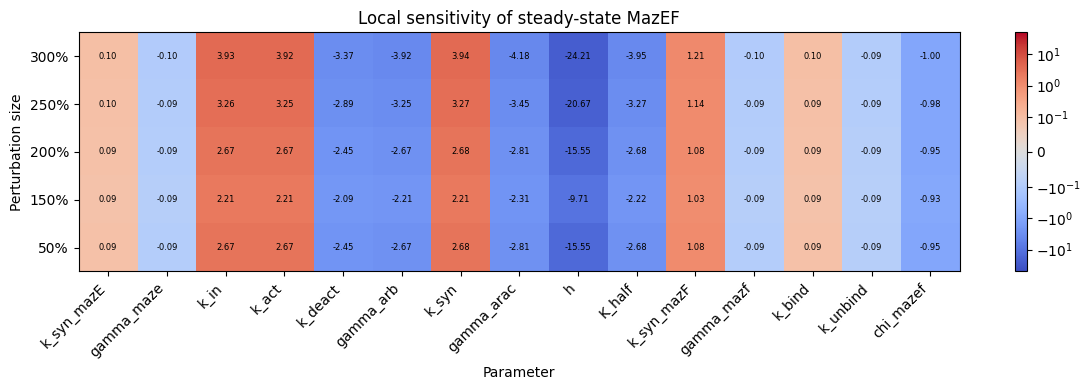

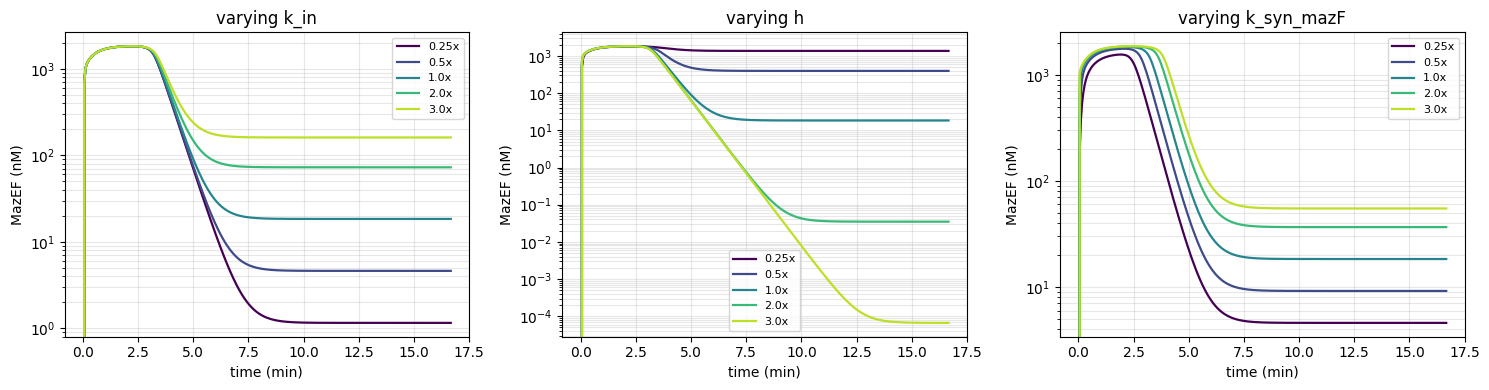

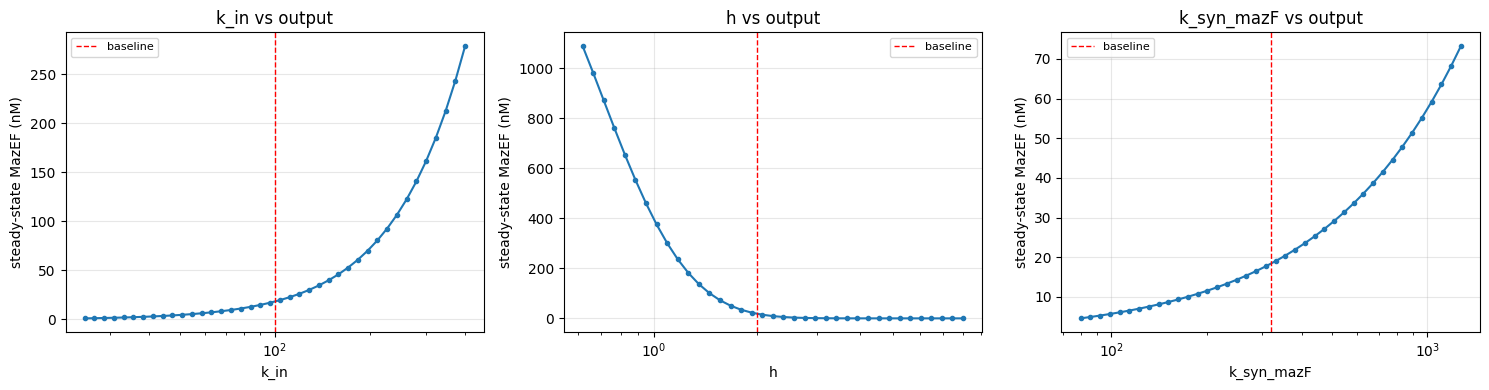

In [5]:
# ------------------ MazEF code ----------------
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from matplotlib.colors import SymLogNorm

# ---------------- parameters ----------------
base = {
'k_syn_mazE':28.32*2,'gamma_maze':0.053,
'k_in':100,'k_act':1e-6,'k_deact':1,'gamma_arb':0.06,
'k_syn':45.3,'gamma_arac':0.0415,'h':2,'K_half':40,
'k_syn_mazF':319.149,'gamma_mazf':0.03,
'k_bind':0.01,'k_unbind':1,'chi_mazef':0.03}

# ---------------- the 6 ODEs, written once ----------------
# MazE and MazF are produced directly as protein (no separate mRNA states)
def rhs(t, v, p):
    p_e,arb,ac,aca,p_f,p_ef = v
    aca_c = max(aca,0)
    return [
        p['k_syn_mazE'] - p['gamma_maze']*p_e + p['k_unbind']*p_ef - p['k_bind']*p_e*p_f,
        p['k_in'] - p['k_act']*arb*ac - p['gamma_arb']*arb + p['k_deact']*aca,
        p['k_syn'] - p['gamma_arac']*ac - p['k_act']*arb*ac + p['k_deact']*aca,
        p['k_act']*arb*ac - p['k_deact']*aca - p['gamma_arac']*aca,
        p['k_syn_mazF']*(aca_c**p['h']/(p['K_half']**p['h']+aca_c**p['h'])) - p['gamma_mazf']*p_f - p['k_bind']*p_e*p_f + p['k_unbind']*p_ef,
        p['k_bind']*p_e*p_f - p['k_unbind']*p_ef - p['chi_mazef']*p_ef]

# MazE starts at its pre-induction steady state (k_syn_mazE / gamma_maze)
y0 = [base['k_syn_mazE']/base['gamma_maze'], 1e8, 40, 0, 0, 0]

# steady state by root-finding
def run_model(p):
    def eqs(v): return rhs(0, v, p)
    sol, info, ier, msg = fsolve(eqs, [0]*6, full_output=True)
    if ier != 1 or any(x < -1e-6 for x in sol) or sol[-1] > 2000:
        return np.nan
    return sol[-1]

# full time course
def trace(p, tmax=1000):
    s = solve_ivp(rhs,[0,tmax],y0,args=(p,),method='BDF',
                  t_eval=np.linspace(0,tmax,300),rtol=1e-6,atol=1e-8)
    return s.t/60, s.y[5]

baseline_output = run_model(base)
print(f"Baseline MazEF: {baseline_output:.3f} nM")
t,y = trace(base)
print(f"Integration check: {y[-1]:.3f} nM")

# ================= FIGURE 1: heatmap =================
P = [0.5,1.5,2,2.5,3]
parameters = list(base.keys())
grid = np.zeros((len(P), len(parameters)))
for row,num in enumerate(P):
    for col,name in enumerate(parameters):
        if base[name]==0: continue
        up=dict(base); up[name]=base[name]*num
        dn=dict(base); dn[name]=base[name]/num
        yu,yd = run_model(up), run_model(dn)
        grid[row,col] = ((yu-yd)/baseline_output)/(2*math.log(num)) \
                        if (np.isfinite(yu) and np.isfinite(yd)) else np.nan

fig,ax = plt.subplots(figsize=(12,4))
im = ax.imshow(grid,cmap='coolwarm',aspect='auto',origin='lower',
               norm=SymLogNorm(linthresh=0.1,vmin=-50,vmax=50))
ax.set_xticks(range(len(parameters))); ax.set_xticklabels(parameters,rotation=45,ha='right')
ax.set_yticks(range(len(P))); ax.set_yticklabels([f'{int(p*100)}%' for p in P])
ax.set_xlabel('Parameter'); ax.set_ylabel('Perturbation size')
ax.set_title('Local sensitivity of steady-state MazEF')
plt.colorbar(im,ax=ax)
for i in range(len(P)):
    for j in range(len(parameters)):
        if np.isfinite(grid[i,j]):
            ax.text(j,i,f'{grid[i,j]:.2f}',ha='center',va='center',color='k',fontsize=6)
plt.tight_layout(); plt.show()

# ================= FIGURE 2: time traces =================
show = ['k_in','h','k_syn_mazF']          # change these to whichever you want
scales = [0.25,0.5,1.0,2.0,3.0]
colors = plt.cm.viridis(np.linspace(0,0.9,len(scales)))

fig,axes = plt.subplots(1,len(show),figsize=(5*len(show),4))
for ax,pname in zip(axes,show):
    for s,c in zip(scales,colors):
        p=dict(base); p[pname]=base[pname]*s
        tt,yy = trace(p)
        ax.plot(tt,yy,color=c,label=f'{s}x',lw=1.6)
    ax.set_yscale('log')
    ax.set_xlabel('time (min)'); ax.set_ylabel('MazEF (nM)')
    ax.set_title(f'varying {pname}'); ax.legend(fontsize=8); ax.grid(alpha=0.3,which='both')
plt.tight_layout(); plt.show()

# ================= FIGURE 3: parameter vs output =================
fig,axes = plt.subplots(1,len(show),figsize=(5*len(show),4))
mult = np.logspace(np.log10(0.25),np.log10(4),40)
for ax,pname in zip(axes,show):
    xs = [base[pname]*m for m in mult]
    ys = []
    for m in mult:
        p=dict(base); p[pname]=base[pname]*m
        ys.append(run_model(p))
    ax.plot(xs,ys,'o-',ms=3)
    ax.axvline(base[pname],color='r',ls='--',lw=1,label='baseline')
    ax.set_xscale('log'); ax.set_xlabel(pname); ax.set_ylabel('steady-state MazEF (nM)')
    ax.set_title(f'{pname} vs output'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Baseline GFP at 30 min: 0.4949


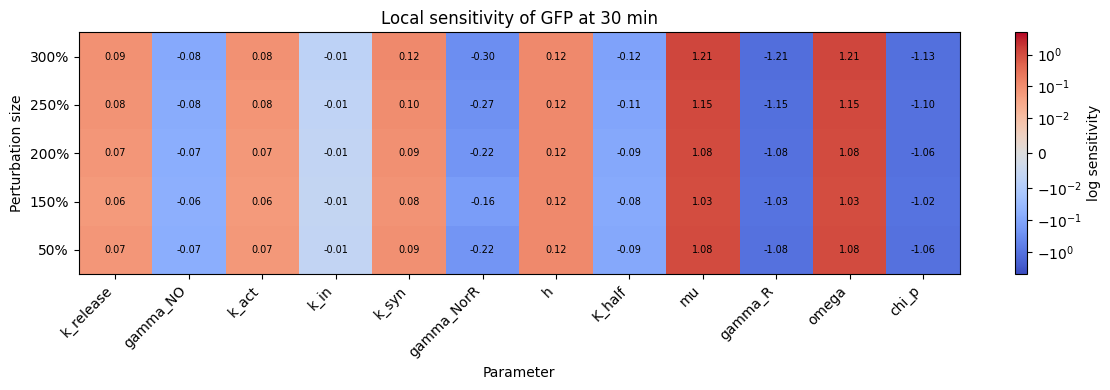

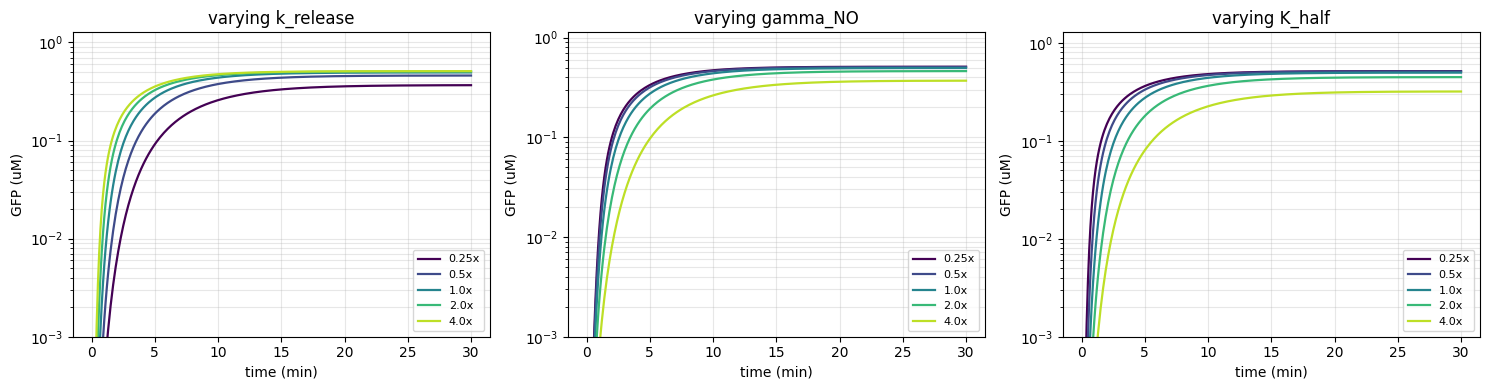

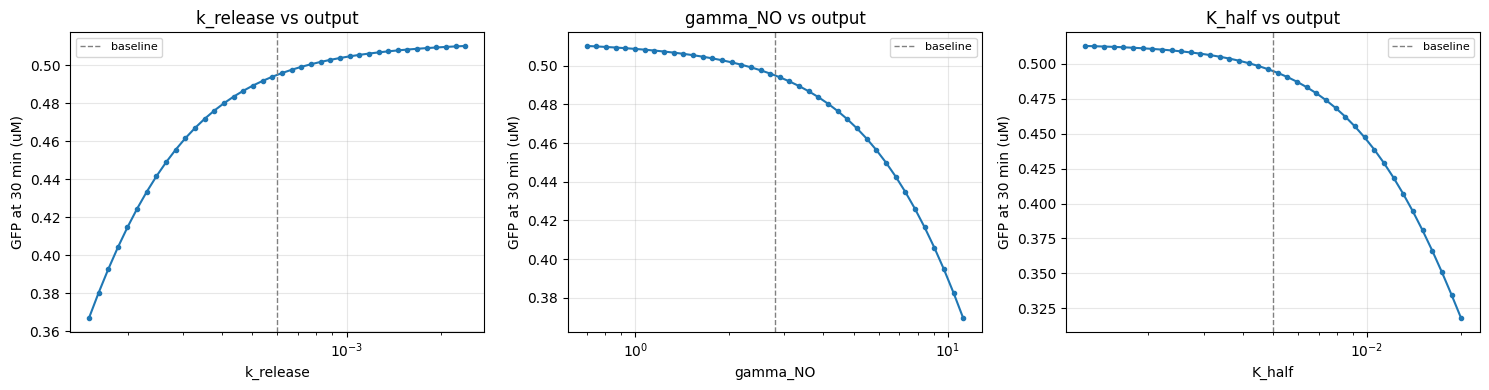

In [4]:
# -------------- NO biosensor ----------------------
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp
from matplotlib.colors import SymLogNorm
from matplotlib.ticker import NullFormatter

# ---------------- baseline parameters ----------------
base = {
'k_release':0.0006,   # DETA-NONOate -> NO release, 1/min
'gamma_NO':2.8,       # NO loss (1.4*2), 1/min
'k_act':1.1183,       # NO + NorR -> NorR*, 1/(uM min)
'k_in':0.036,         # NorR* -> NorR + NO, 1/min
'k_syn':0.03,         # NorR synthesis, uM/min
'gamma_NorR':0.3,     # NorR degradation, 1/min
'h':2,                # Hill coefficient
'K_half':0.005,       # half-max NorR*, uM
'mu':0.0058,          # transcription rate
'gamma_R':0.376,      # mRNA degradation
'omega':10,           # translation rate
'chi_p':0.3}          # GFP degradation, 1/min

# ---------------- the model ----------------
def rhs(t, v, p):
    donor, NO, NorR, NorR_a, GFP = v
    release  = p['k_release']*donor
    NO_c     = max(NO,0)
    NorR_c   = max(NorR,0)
    NorR_a_c = max(NorR_a,0)
    act = p['k_act']*NO_c*NorR_c
    return [
        -release,
        release + p['k_in']*NorR_a_c - p['gamma_NO']*NO - act,
        p['k_syn'] - p['gamma_NorR']*NorR + p['k_in']*NorR_a_c - act,
        act - p['k_in']*NorR_a_c - p['gamma_NorR']*NorR_a,
        (p['omega']*p['mu']/p['gamma_R'])*(NorR_a_c**p['h']/(p['K_half']**p['h']+NorR_a_c**p['h']))
            - p['chi_p']*GFP]

y0   = [500.0, 0.0, 0.017, 0.0, 0.0]   # donor, NO, NorR, NorR*, GFP
TMAX = 30.0                            # minutes
def run_model(p, tmax=TMAX):
    s = solve_ivp(rhs,[0,tmax],y0,args=(p,),method='BDF',rtol=1e-8,atol=1e-10)
    if not s.success:
        return np.nan
    return s.y[4][-1]
def trace(p, tmax=TMAX):
    s = solve_ivp(rhs,[0,tmax],y0,args=(p,),method='BDF',
                  t_eval=np.linspace(0,tmax,300),rtol=1e-8,atol=1e-10)
    return s.t, s.y[4]
params   = list(base.keys())
baseline = run_model(base)
print("Baseline GFP at %g min: %.4f" % (TMAX, baseline))

# ================= FIGURE 1: heatmap =================
P = [0.5, 1.5, 2, 2.5, 3]
grid = np.full((len(P), len(params)), np.nan)
for row, num in enumerate(P):
    for col, name in enumerate(params):
        if base[name] == 0 or num == 1:
            continue
        up, down = dict(base), dict(base)
        up[name]   = base[name]*num
        down[name] = base[name]/num
        y_up, y_down = run_model(up), run_model(down)
        if not (np.isfinite(y_up) and np.isfinite(y_down)):
            continue
        grid[row, col] = ((y_up - y_down)/baseline)/(2*math.log(num))

fig, ax = plt.subplots(figsize=(12,4))
norm = SymLogNorm(linthresh=0.01, vmin=-5, vmax=5)
im = ax.imshow(grid, cmap='coolwarm', norm=norm, aspect='auto', origin='lower')
ax.set_xticks(range(len(params))); ax.set_xticklabels(params, rotation=45, ha='right')
ax.set_yticks(range(len(P)));      ax.set_yticklabels([f'{int(p*100)}%' for p in P])
ax.set_xlabel('Parameter'); ax.set_ylabel('Perturbation size')
ax.set_title('Local sensitivity of GFP at 30 min')
fig.colorbar(im, ax=ax, label="log sensitivity")
for r in range(len(P)):
    for c in range(len(params)):
        if np.isfinite(grid[r,c]):
            ax.text(c, r, f"{grid[r,c]:.2f}", ha='center', va='center', fontsize=7)
plt.tight_layout(); plt.show()

# ================= FIGURE 2: time traces =================
show   = ['k_release','gamma_NO','K_half']   # change these to whichever you want
scales = [0.25, 0.5, 1.0, 2.0, 4.0]
colors = plt.cm.viridis(np.linspace(0,0.9,len(scales)))

fig, axes = plt.subplots(1, len(show), figsize=(5*len(show),4))
for ax, name in zip(axes, show):
    for s, color in zip(scales, colors):
        p = dict(base); p[name] = base[name]*s
        t, g = trace(p)
        ax.plot(t, g, color=color, label=f'{s}x', lw=1.6)
    ax.set_yscale('log'); ax.set_ylim(bottom=1e-3)   # skip the near-zero start so curves are readable
    ax.set_xlabel('time (min)'); ax.set_ylabel('GFP (uM)')
    ax.set_title(f'varying {name}'); ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

# ================= FIGURE 3: parameter vs output =================
sweep = np.logspace(np.log10(0.25), np.log10(4), 40)
fig, axes = plt.subplots(1, len(show), figsize=(5*len(show),4))
for ax, name in zip(axes, show):
    xs  = [base[name]*s for s in sweep]
    out = []
    for s in sweep:
        p = dict(base); p[name] = base[name]*s
        out.append(run_model(p))
    ax.plot(xs, out, 'o-', ms=3)
    ax.axvline(base[name], ls='--', c='gray', lw=1, label='baseline')
    ax.set_xscale('log'); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xlabel(name); ax.set_ylabel('GFP at 30 min (uM)')
    ax.set_title(f'{name} vs output'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()